Workflow:
- Scaricare il dataset
- Modellare il dataset: rimuovere colonne, valori mancanti
- Selezione delle feature: quelle che non sono molto correlate tra loro

- Split dei dati: 80/20
- Primo modello di Decision Tree -> dummy
- Tuning degli iperparametri: prima Random Search poi Grid Search
- Pruning dell'albero trovato
- Secondo modello di Decision Tree -> migliore

- Provare a dare un peso per le varie istanze !

- Bagging e Boosting classici sui modelli ottimizzati
- Random Forest -> dummy
- Tuning dei parametri della Random Forest
- Con Random Forest: trova le migliori feature, Outliers e missing value imputation 

- Creazione di nuove feature? Magari combinare alcune che erano molto correlate in una sola ???

In [221]:
import numpy as np
import pandas as pd


# Scarichiamo e leggiamo i dati del train.csv file
df = pd.read_csv("dati/train.csv")
df.head()

,id,Basic_Demos-Enroll_Season,Basic_Demos-Age,Basic_Demos-Sex,CGAS-Season,CGAS-CGAS_Score,Physical-Season,Physical-BMI,Physical-Height,Physical-Weight,...,PCIAT-PCIAT_18,PCIAT-PCIAT_19,PCIAT-PCIAT_20,PCIAT-PCIAT_Total,SDS-Season,SDS-SDS_Total_Raw,SDS-SDS_Total_T,PreInt_EduHx-Season,PreInt_EduHx-computerinternet_hoursday,sii
0,00008ff9,Fall,5,0,Winter,51,Fall,16.87731569,46.0,50.8,...,4,2,4,55,,,,Fall,3,2
1,000fd460,Summer,9,0,,,Fall,14.03559028,48.0,46.0,...,0,0,0,0,Fall,46,64,Summer,0,0
2,00105258,Summer,10,1,Fall,71,Fall,16.64869606,56.5,75.6,...,2,1,1,28,Fall,38,54,Summer,2,0
3,00115b9f,Winter,9,0,Fall,71,Summer,18.29234694,56.0,81.6,...,3,4,1,44,Summer,31,45,Winter,0,1
4,0016bb22,Spring,18,1,Summer,,,,,,...,,,,,,,,,,


In [222]:
print("Valori da predire:", df['sii'].unique())
print("Valori nulli nella colonna target:", df['sii'].isna().sum())
print("Tipo della classe target:", df['sii'].dtype)

Valori da predire: ['  2' '  0' '  1' '   ' '  3']
Valori nulli nella colonna target: 0
Tipo della classe target: object


In [223]:
# I dati mancanti non sono NaN, ma sono spazi ("   ")
# Sostituiamo le stringhe vuote della colonna 'sii' ("   ") con NaN
df['sii'] = df['sii'].str.strip()
df['sii'] = df['sii'].replace("", np.nan)
print("Valori nulli nella colonna target prima del drop:", df['sii'].isna().sum())

# Eliminiamuo le righe con valori NaN nella colonna 'sii'
df = df.dropna(subset=['sii'])
print("Valori nulli nella colonna target dopo il drop:", df['sii'].isna().sum())

# Convertiamo la colonna 'sii' in numerica
df['sii'] = df['sii'].astype(float)
print("Tipo della classe target:", df['sii'].dtype)

Valori nulli nella colonna target prima del drop: 1224
Valori nulli nella colonna target dopo il drop: 0
Tipo della classe target: float64


In [224]:
# Sostituisco tutti i valori nulli nel dataset, che sono spazi "   ", con NaN
for col in df.select_dtypes(include=['object']).columns: 
    df[col] = df[col].str.strip()
    df[col] = df[col].replace(r'^\s*$', np.nan, regex=True)

In [225]:
# Traduciamo le varibili categoriali in numeriche
categorical_features = [col for col in df.columns if col.endswith("_Season ") or col.endswith("-Season ")]
season_mapping = {
    "Summer": 0,
    "Fall": 1,
    "Winter": 2,
    "Spring": 3,
}

for col in categorical_features:
    # df[col].fillna(df[col].mode()[0], inplace=True) # rimpiazziamo il valore nullo con la moda
    df[col] = df[col].map(season_mapping)

# Eliminiamo la colonna id -> non serve
# traduciamo l'intero dataset in float
# Eliminiamo le righe che hanno peso == 0 -> impossibile
# Sostiuiamo i valori nulli con la media della rispettiva colonna

df = df.drop(columns=['id       '])
df = df.astype(float)

print(df["Physical-Weight "].min())
print(df["Physical-Weight "].max())

zero_weight_rows = df[df['Physical-Weight '] == 0]
zero_weight_indices = zero_weight_rows.index 

df = df.drop(zero_weight_indices)
print(f"Numero di osservazioni dopo la rimozione: {df.shape[0]}")

0.0
315.0
Numero di osservazioni dopo la rimozione: 2684


In [226]:
# Elimino le colonne che hanno più del 40% di valori mancanti e che non sono molto correlate con la variabile target
missing_threshold = 0.4

missing_percentage = df.isnull().mean()

columns_to_drop = missing_percentage[missing_percentage > missing_threshold].index
# df = df.drop(columns=columns_to_drop)

print(f"Columns dropped: {list(columns_to_drop)}")

correlation_with_target = df[columns_to_drop].corrwith(df['sii']).abs().sort_values(ascending=False)

print("Correlation of high-missing features with target:")
print(correlation_with_target)

high_corr_features = correlation_with_target[correlation_with_target > 0.10].index  
columns_to_really_drop = set(columns_to_drop) - set(high_corr_features)

print(f"Columns actually dropped: {list(columns_to_really_drop)}")
print(f"Columns retained due to correlation: {list(high_corr_features)}")

df = df.drop(columns=columns_to_really_drop)

Columns dropped: ['Physical-Waist_Circumference ', 'Fitness_Endurance-Season ', 'Fitness_Endurance-Max_Stage ', 'Fitness_Endurance-Time_Mins ', 'Fitness_Endurance-Time_Sec ', 'FGC-FGC_GSND ', 'FGC-FGC_GSND_Zone ', 'FGC-FGC_GSD ', 'FGC-FGC_GSD_Zone ', 'PAQ_A-Season ', 'PAQ_A-PAQ_A_Total ', 'PAQ_C-Season ', 'PAQ_C-PAQ_C_Total ']
Correlation of high-missing features with target:
Physical-Waist_Circumference     0.272885
FGC-FGC_GSD                      0.163448
FGC-FGC_GSND                     0.149495
Fitness_Endurance-Max_Stage      0.070589
Fitness_Endurance-Time_Mins      0.060628
PAQ_A-PAQ_A_Total                0.045968
PAQ_C-Season                     0.032939
PAQ_A-Season                     0.025298
FGC-FGC_GSD_Zone                 0.023696
Fitness_Endurance-Time_Sec       0.008701
PAQ_C-PAQ_C_Total                0.004365
Fitness_Endurance-Season         0.003978
FGC-FGC_GSND_Zone                0.001667
dtype: float64
Columns actually dropped: ['PAQ_A-PAQ_A_Total ', 'FGC-FGC_GS

In [227]:
columnsOfInterest = df.columns
nan_counts = df.loc[:, columnsOfInterest].isna().sum()
nan_counts

Basic_Demos-Enroll_Season                    0
Basic_Demos-Age                              0
Basic_Demos-Sex                              0
CGAS-Season                                387
CGAS-CGAS_Score                            387
                                          ... 
SDS-SDS_Total_Raw                          209
SDS-SDS_Total_T                            211
PreInt_EduHx-Season                         17
PreInt_EduHx-computerinternet_hoursday      79
sii                                          0
Length: 71, dtype: int64

In [228]:
# for col in df.columns:
#    df[col].fillna(round(df[col].mean()), inplace=True)

# df = df.round(2)

In [229]:
# la colonna sii è derivata direttamente dalle colonne PCIAT-PCIAT_* -> non possiamo tenerle in considerazione
X = df.drop(columns=['sii'] + [col for col in df.columns if col.startswith('PCIAT-PCIAT')])
y = df['sii']
X.shape, y.shape

((2684, 49), (2684,))

In [230]:
import pandas as pd
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

original_column_names = X.columns

impute_it = IterativeImputer()
X = impute_it.fit_transform(X)

X = pd.DataFrame(X, columns=original_column_names) 

In [231]:
for col in X.columns:
   if col.endswith('-Season ') or col.endswith('_Season '):
      X[col] = X[col].round()


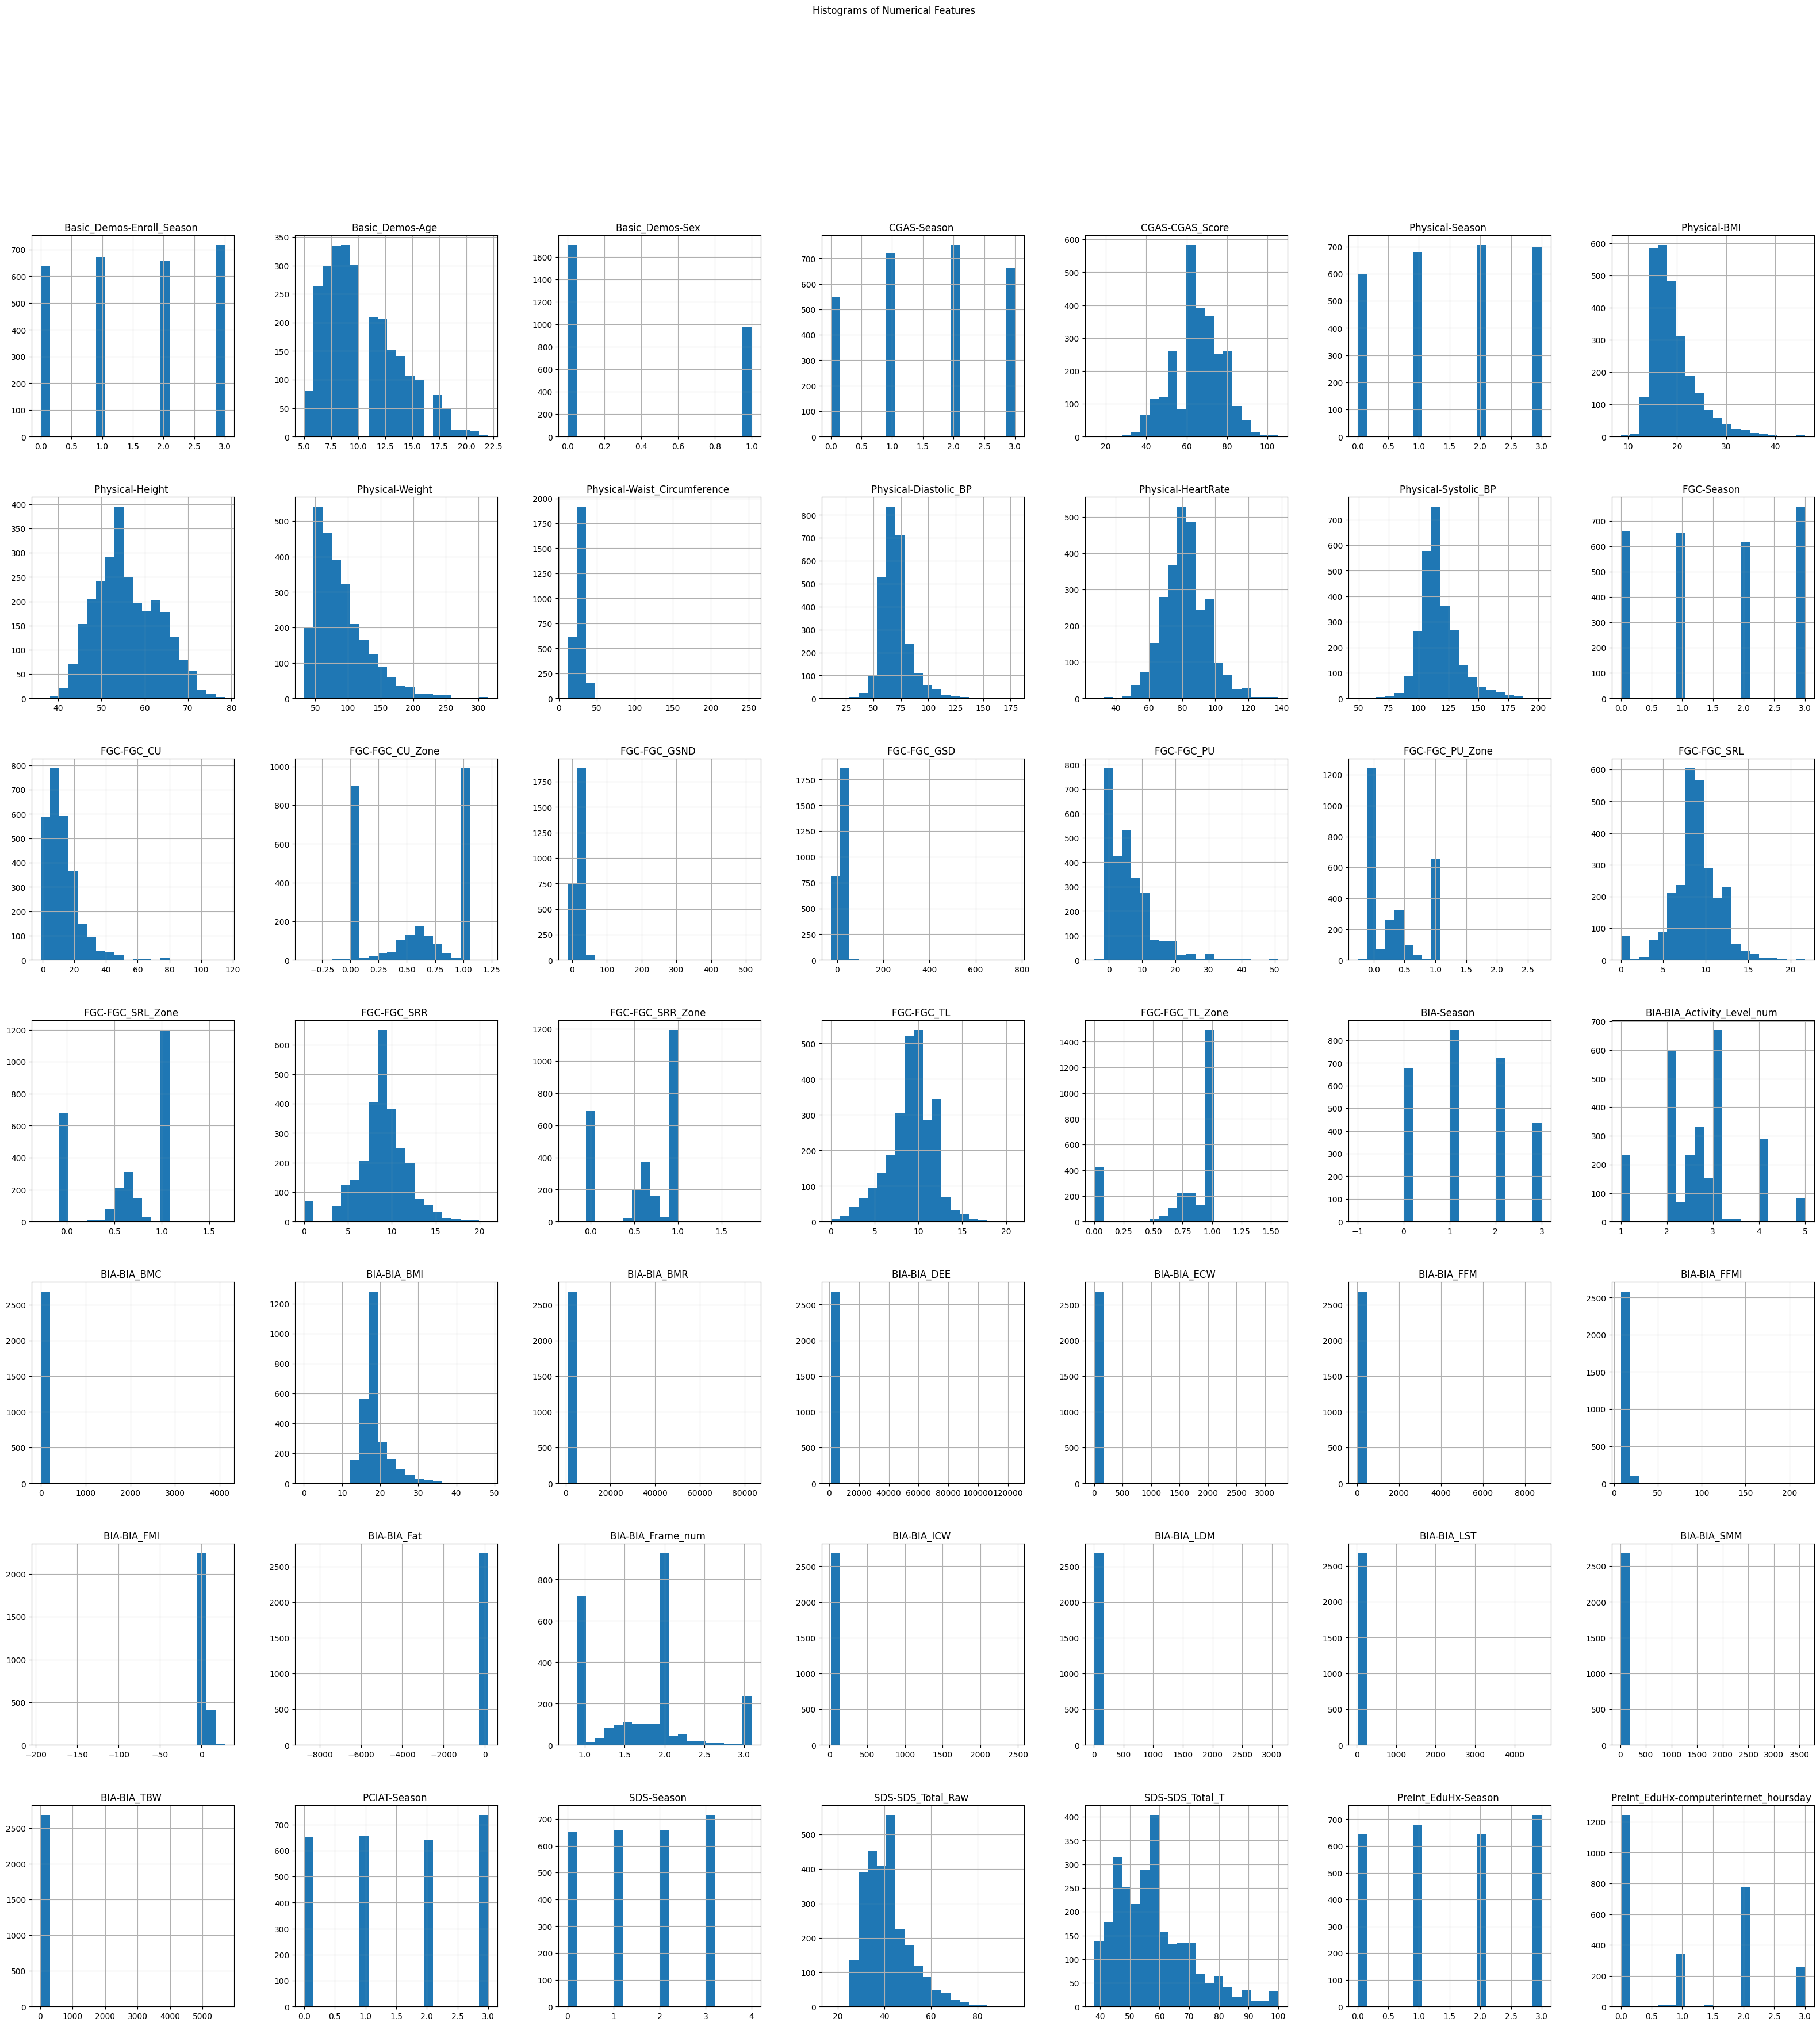

In [232]:
# Visualizzo le varibili usando gli istogrammi
import matplotlib.pyplot as plt

X.hist(bins=20, figsize=(40, 40))
plt.suptitle("Histograms of Numerical Features")
plt.show()


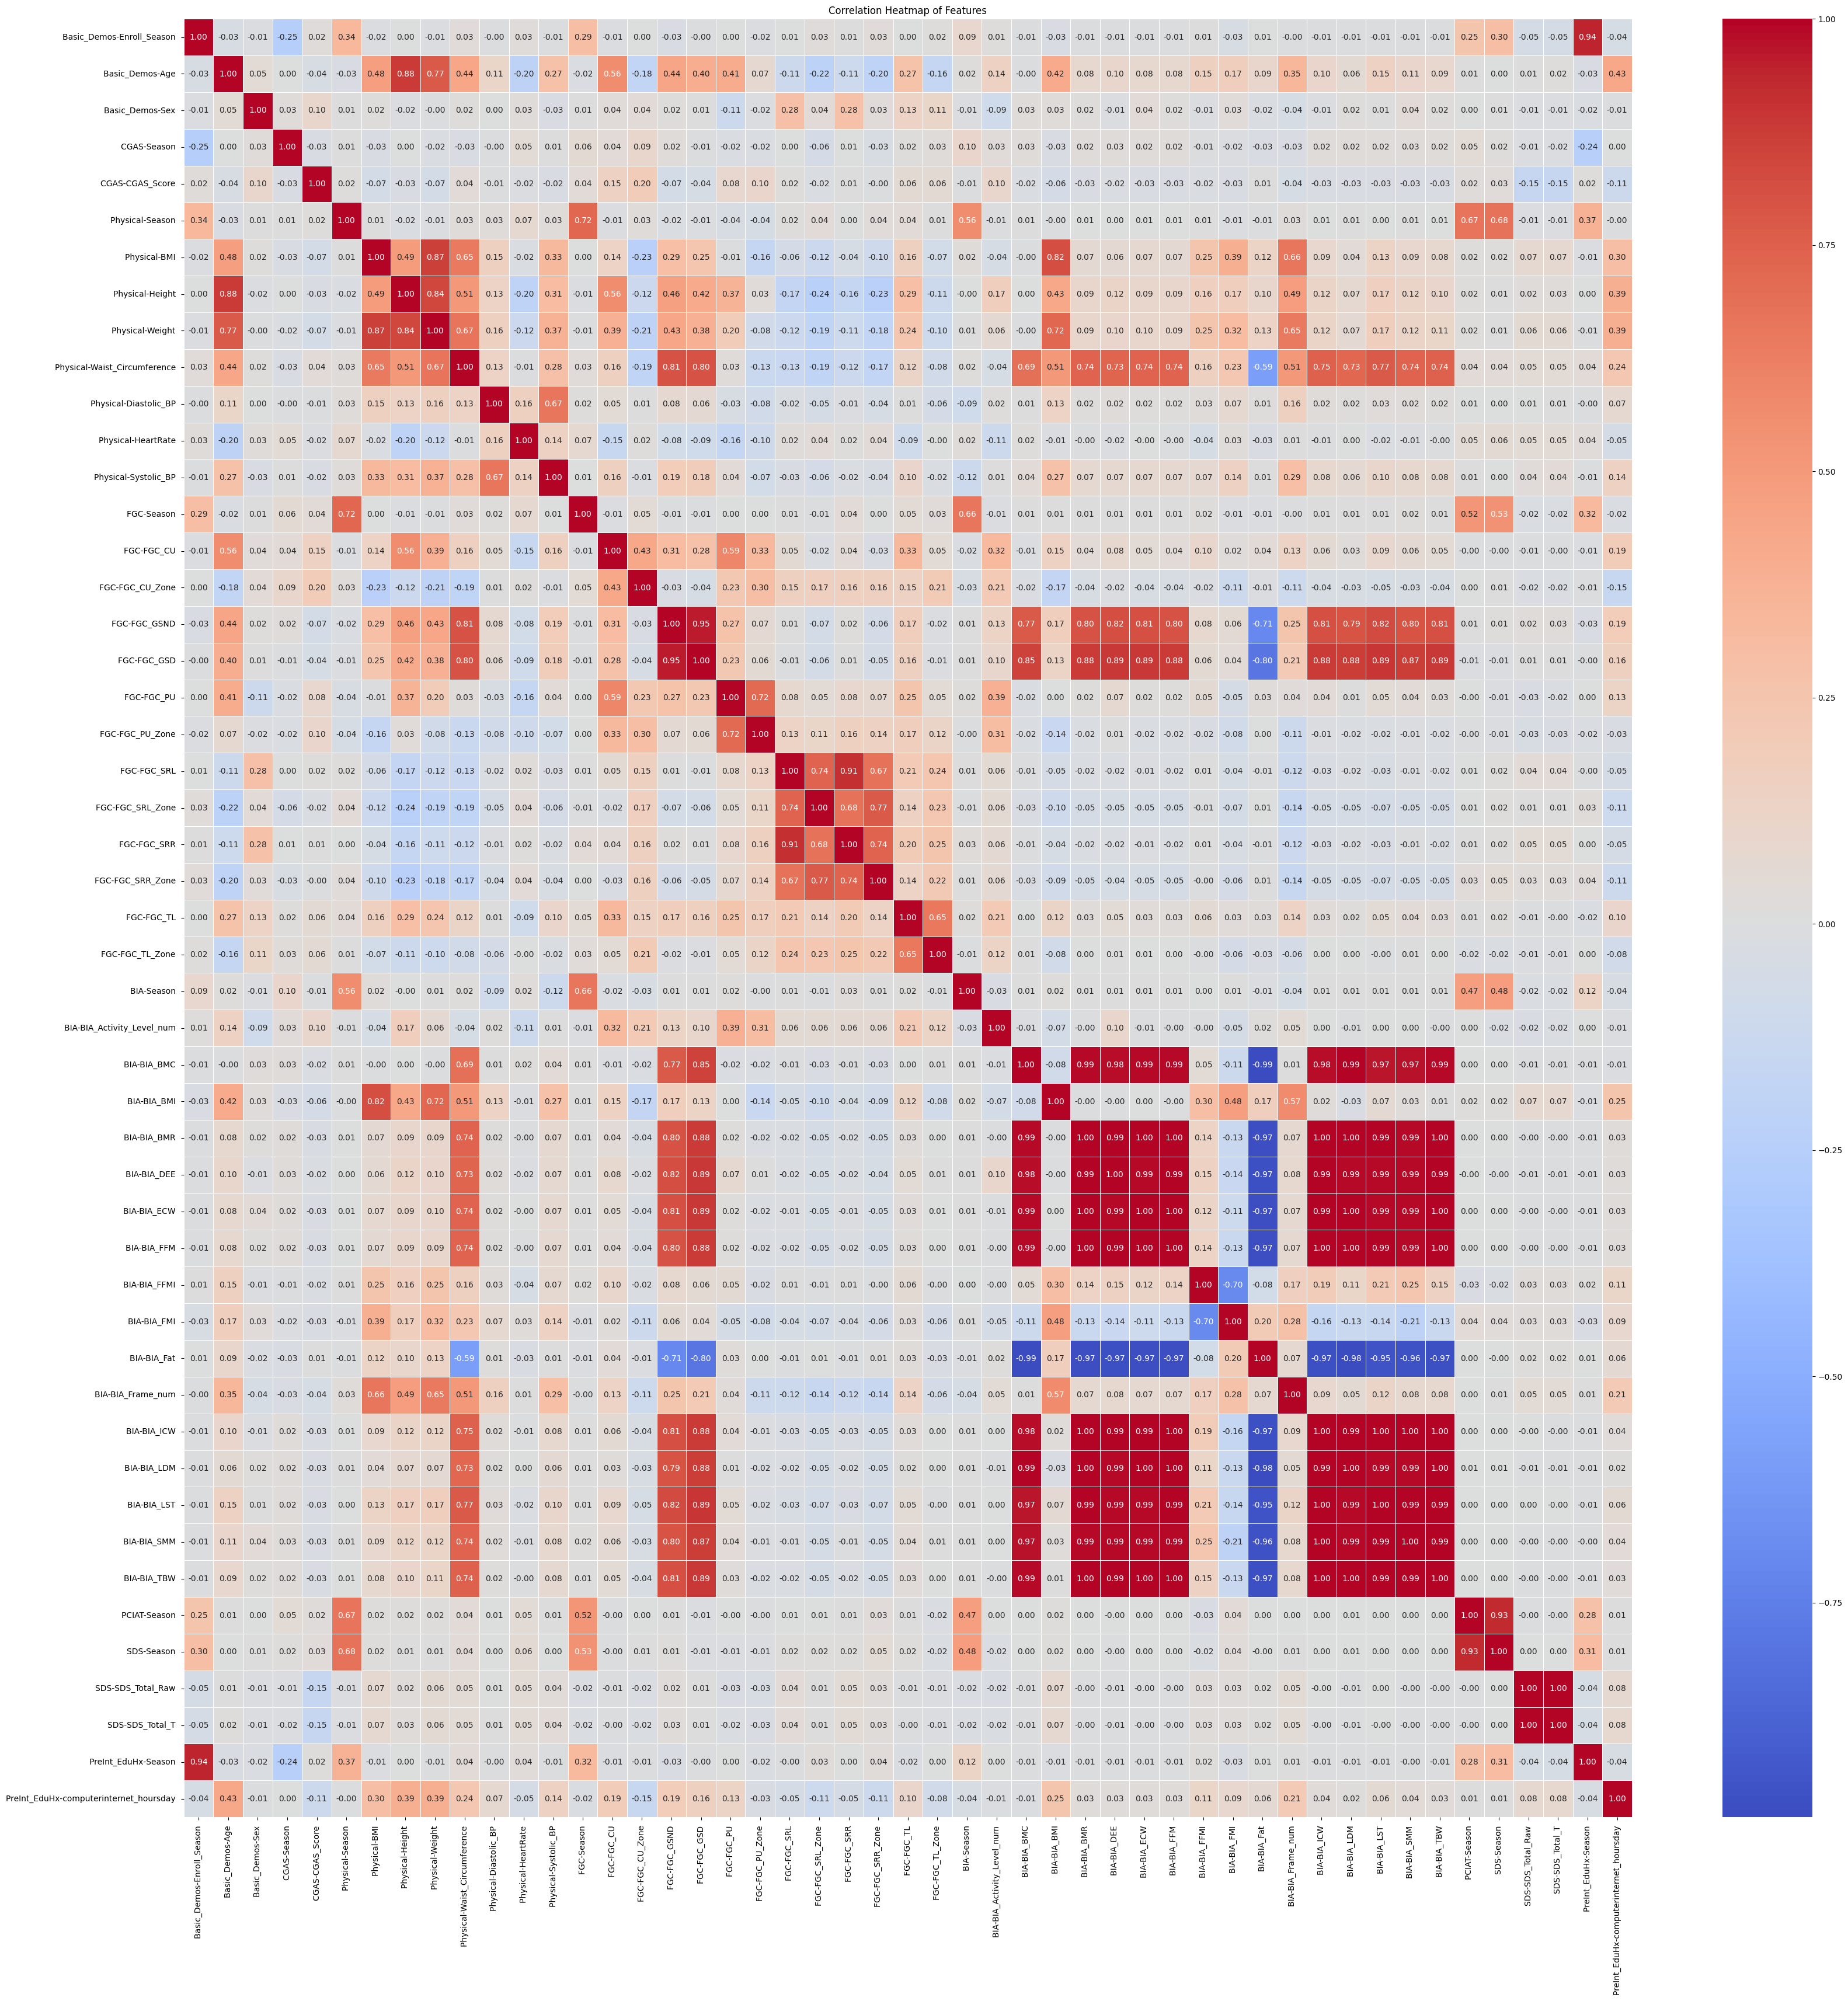

In [233]:
import seaborn as sns

# Calculate correlation matrix
corr_matrix = X.corr()

# Plot heatmap
plt.figure(figsize=(40, 40))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Features")
plt.show()


Dropped features: ['Physical-Height ', 'Physical-Weight ', 'FGC-Season ', 'FGC-FGC_GSND ', 'FGC-FGC_GSD ', 'FGC-FGC_PU_Zone ', 'FGC-FGC_SRL_Zone ', 'FGC-FGC_SRR ', 'FGC-FGC_SRR_Zone ', 'BIA-BIA_BMC ', 'BIA-BIA_BMI ', 'BIA-BIA_BMR ', 'BIA-BIA_DEE ', 'BIA-BIA_ECW ', 'BIA-BIA_FFM ', 'BIA-BIA_Fat ', 'BIA-BIA_ICW ', 'BIA-BIA_LDM ', 'BIA-BIA_LST ', 'BIA-BIA_SMM ', 'BIA-BIA_TBW ', 'SDS-Season ', 'SDS-SDS_Total_T ', 'PreInt_EduHx-Season ']


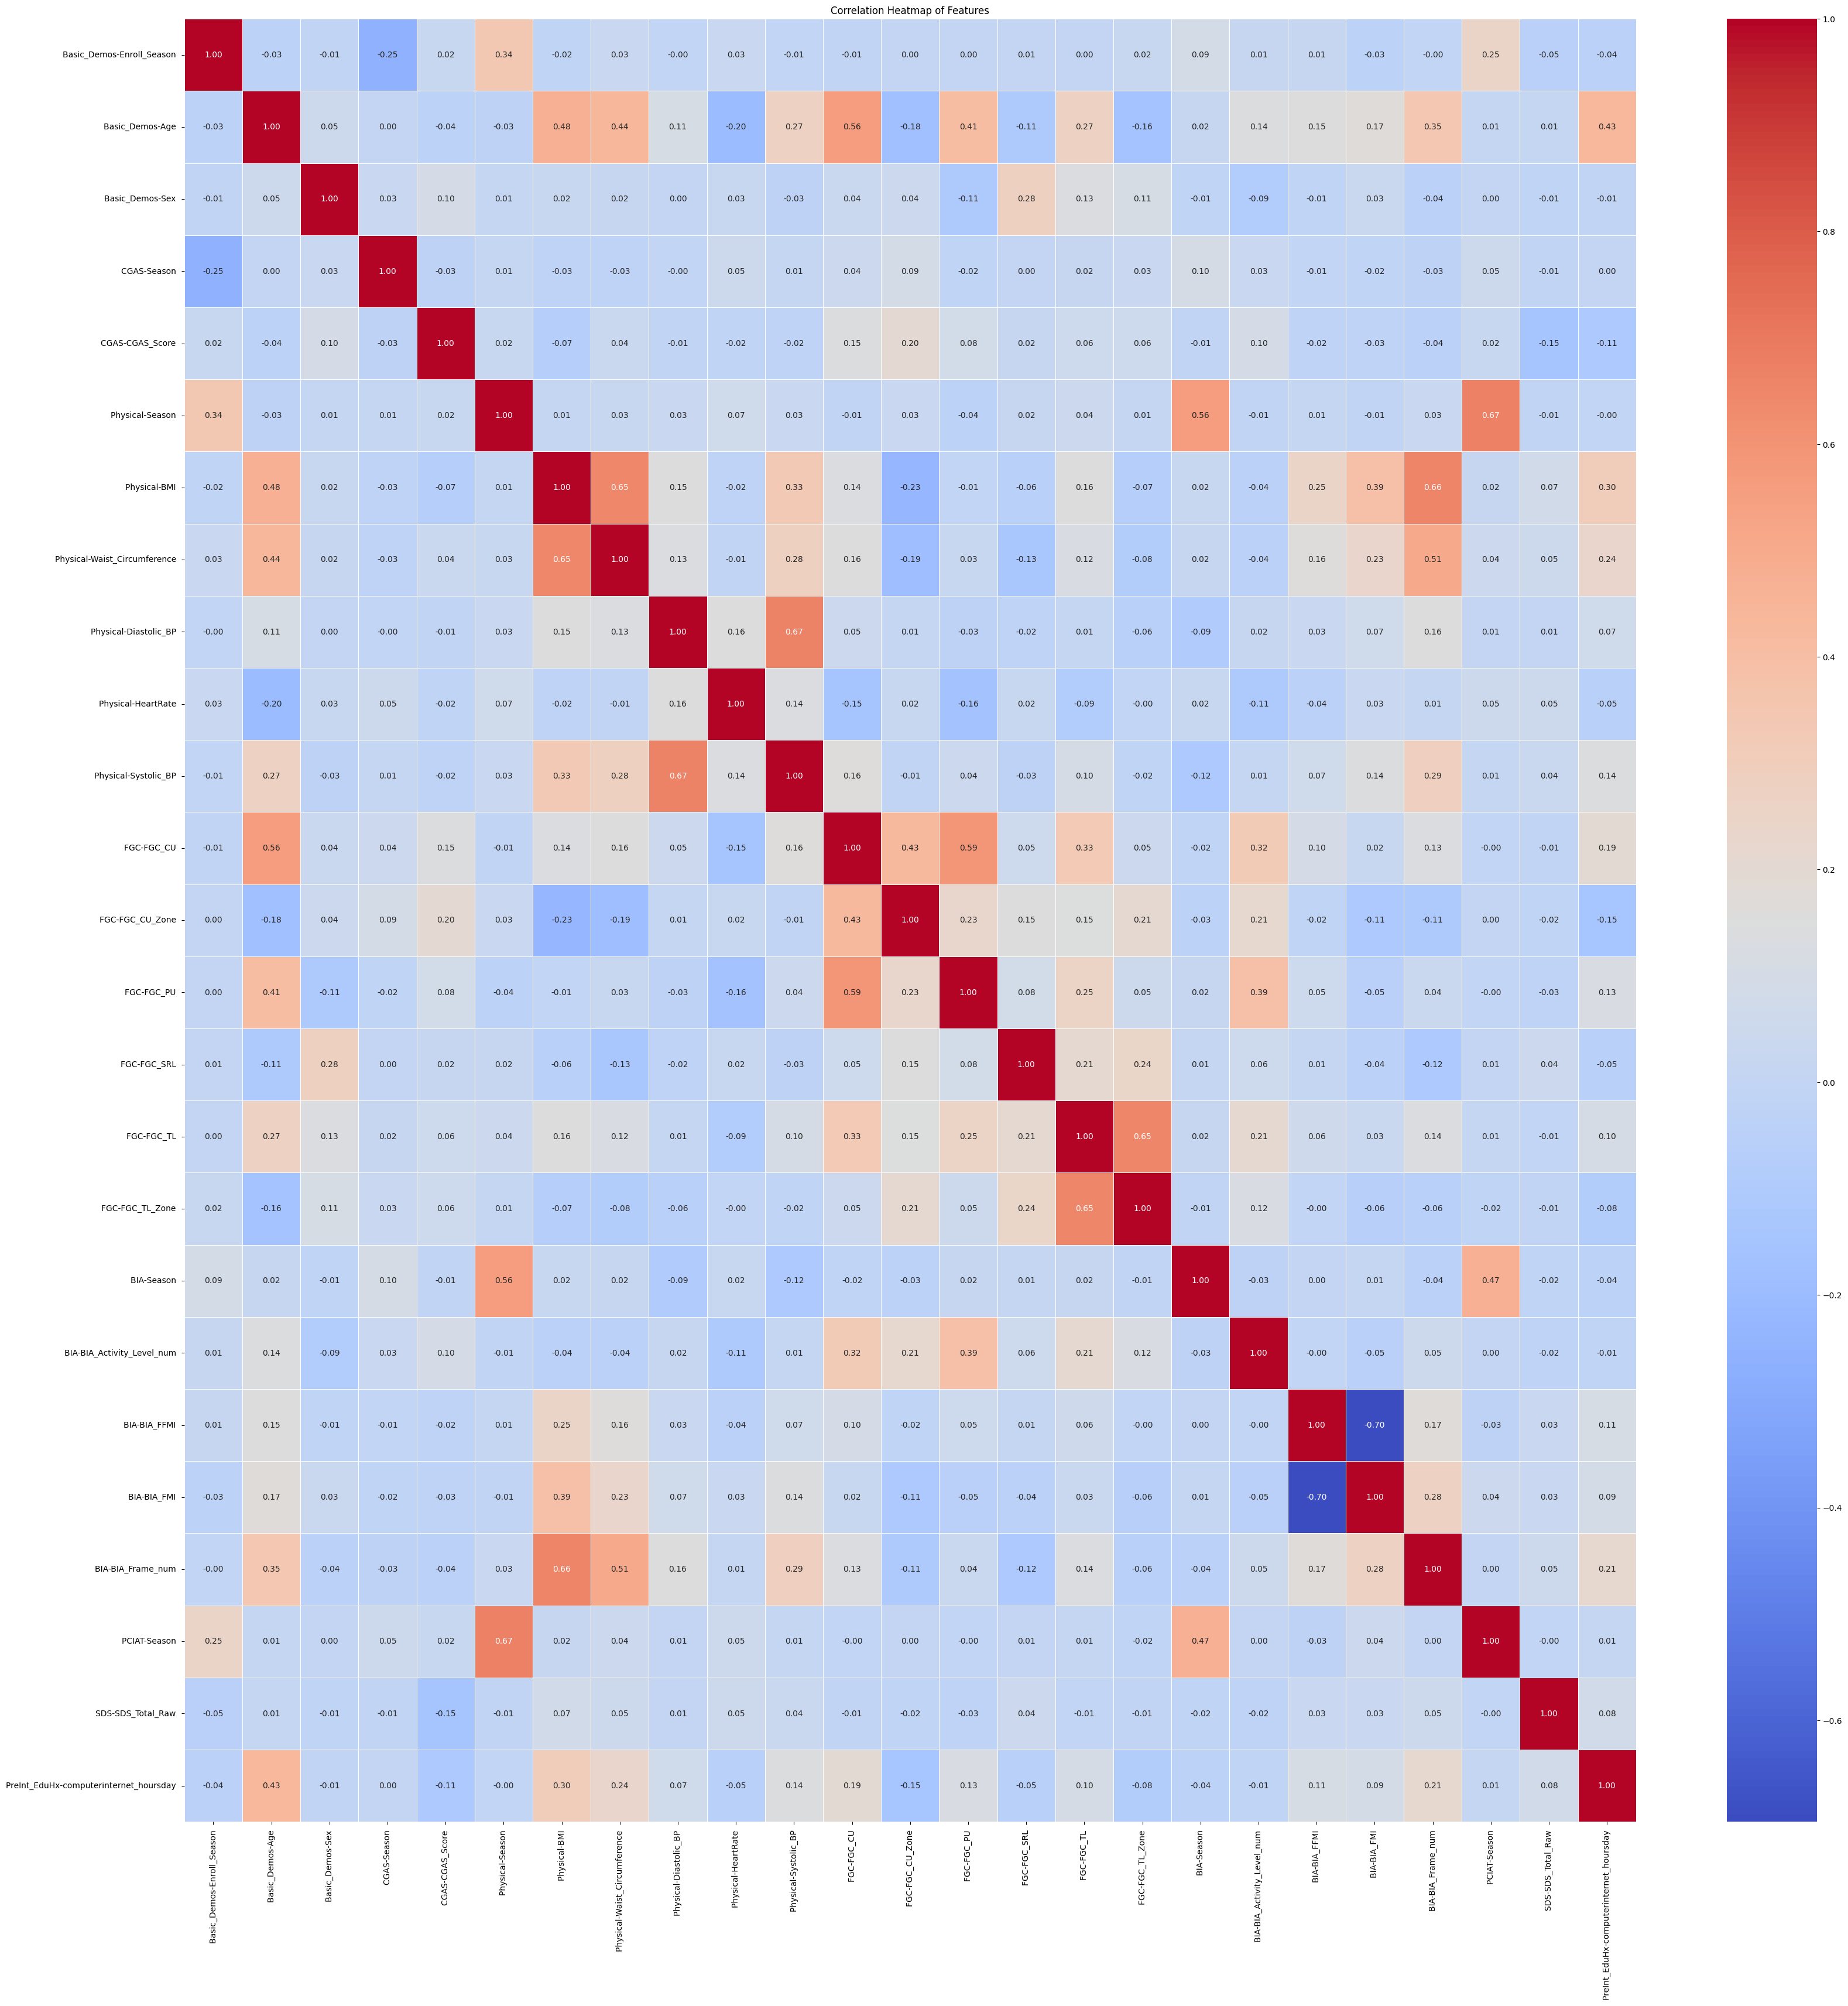

In [234]:
# Droppiamo le feature con una correlazione > di 0.7 o < di -0.7 -> Troppo correlate tra loro
import pandas as pd

threshold = 0.7

upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [column for column in upper.columns if any(abs(upper[column]) >= threshold)]

X = X.drop(columns=to_drop)

print(f"Dropped features: {to_drop}")
X.shape


import seaborn as sns

# Riguardiamo la matrice di correlazione
corr_matrix = X.corr()

# Plot heatmap
plt.figure(figsize=(40, 40))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Features")
plt.show()

In [235]:
# memorizziamo le colonne che hanno rispettato tutti i criteri fino ad ora
# controlliamo che non ci siano valori nulli
columnsOfInterest = X.columns
nan_counts = X.loc[:, columnsOfInterest].isna().sum()
nan_counts

Basic_Demos-Enroll_Season                  0
Basic_Demos-Age                            0
Basic_Demos-Sex                            0
CGAS-Season                                0
CGAS-CGAS_Score                            0
Physical-Season                            0
Physical-BMI                               0
Physical-Waist_Circumference               0
Physical-Diastolic_BP                      0
Physical-HeartRate                         0
Physical-Systolic_BP                       0
FGC-FGC_CU                                 0
FGC-FGC_CU_Zone                            0
FGC-FGC_PU                                 0
FGC-FGC_SRL                                0
FGC-FGC_TL                                 0
FGC-FGC_TL_Zone                            0
BIA-Season                                 0
BIA-BIA_Activity_Level_num                 0
BIA-BIA_FFMI                               0
BIA-BIA_FMI                                0
BIA-BIA_Frame_num                          0
PCIAT-Seas

In [236]:
print("X shape", X.shape)

y = df.loc[:, 'sii']
print("y shape", y.shape)

# Contiamo quanti valori ci sono per ogni classe
# in questo modo capiamo qual è la soglia minima
# predicendo sempre la classe più frequente
print(y.value_counts(normalize=True))


from sklearn.model_selection import train_test_split

X_train80, X_test20, y_train80, y_test20 = train_test_split(X, y, test_size=0.20, random_state=42)



X shape (2684, 25)
y shape (2684,)
sii
0.0    0.581222
1.0    0.267511
2.0    0.138599
3.0    0.012668
Name: proportion, dtype: float64


In [237]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Proviamo con un albero di decisione con tutti i parametri di default

decTree = DecisionTreeClassifier(random_state=42)
decTree.fit(X_train80,y_train80)

print("Train acc:", accuracy_score(y_true = y_train80, y_pred = decTree.predict(X_train80))) # -> overfitting!
print("Test acc:", accuracy_score(y_true = y_test20,  y_pred = decTree.predict(X_test20)))

from sklearn.model_selection import cross_val_score

scores = cross_val_score(decTree, X_train80, y_train80, cv=10)
print("Accuracy media con cv=20:", scores.mean())

Train acc: 1.0
Test acc: 0.521415270018622
Accuracy media con cv=20: 0.48719626168224306


In [238]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

#
# Modello usando un albero di decisione
# usando come stopping criteria il numero di foglie
# split: 80/20
#

best_leaves = None
best_cv_acc = 0
for max_leaves in range(2,50):
    decTree = DecisionTreeClassifier(max_leaf_nodes=max_leaves, random_state=42)

    cv_scores = cross_val_score(decTree, X_train80, y_train80, cv=20, scoring='accuracy')
    mean_cv_acc = np.mean(cv_scores)
    
    # Save the best max_leaf_nodes
    if mean_cv_acc > best_cv_acc:
        best_cv_acc = mean_cv_acc
        best_leaves = max_leaves

print(f"Il miglior numero di foglie è {best_leaves} con una cross-validation accuracy di {best_cv_acc:.3f}")

Il miglior numero di foglie è 5 con una cross-validation accuracy di 0.608


In [239]:
#
# Modello usando un albero di decisione
# usando come stopping criteria la profondità
# split: 80/20
#

bestDepth = None
best_cv_acc = 0

for max_depth in range(1, 20):
    decTree = DecisionTreeClassifier(max_depth=max_depth, random_state=42)
    cv_scores = cross_val_score(decTree, X_train80, y_train80, cv=20, scoring='accuracy')
    mean_cv_acc = np.mean(cv_scores)
    
    if mean_cv_acc > best_cv_acc:
        best_cv_acc = mean_cv_acc
        bestDepth = max_depth

print(f"Il miglior numero di profondità è {bestDepth} con una cross-validation accuracy di {best_cv_acc:.3f}")


Il miglior numero di profondità è 3 con una cross-validation accuracy di 0.607


In [240]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.tree import DecisionTreeClassifier
import numpy as np
from scipy.stats import randint

#
# Tuning dei parametri
# Iniziamo con una RandomizedSearchCV
# 

param_dist = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [5, 10, 15, 20, 30, 40, 50, 60, 70],
    'min_samples_split': [2, 5, 10, 15, 20, 25, 30, 50, 70, 90],
    'min_samples_leaf': [1, 5, 10, 15, 20, 25, 30, 50, 70, 90],
    'max_features': [None, 'sqrt', 'log2'],
    # 'min_weight_fraction_leaf': [0.0, 0.05, 
    #                              0.1, 0.15, 
    #                              0.2,],
}

tree = DecisionTreeClassifier(random_state=42)
random_search = RandomizedSearchCV(estimator=tree, param_distributions=param_dist, 
                                   n_iter=1000, cv=20, scoring="accuracy", random_state=42, n_jobs=-1)
random_search.fit(X_train80, y_train80)

best_params_random = random_search.best_params_
print("Best parameters:", best_params_random)


Best parameters: {'min_samples_split': 50, 'min_samples_leaf': 50, 'max_features': 'sqrt', 'max_depth': 5, 'criterion': 'entropy'}


In [241]:
print(random_search.best_estimator_)
best_tree = random_search.best_estimator_
best_tree.fit(X_train80, y_train80)

train_acc = accuracy_score(y_true=y_train80, y_pred=best_tree.predict(X_train80))
test_acc = accuracy_score(y_true=y_test20, y_pred=best_tree.predict(X_test20))
print(f"Train Accuracy: {train_acc:.3f}")
print(f"Test Accuracy: {test_acc:.3f}")

scores = cross_val_score(best_tree, X_train80, y_train80, cv=20, scoring='accuracy')
print(f"Cross-Validation Accuracy: {scores.mean():.4f} ± {scores.std():.4f}")

feature_importances = best_tree.feature_importances_
importance_df = pd.Series(feature_importances, index=X_train80.columns).sort_values(ascending=False)

print("Top features based on importance:")
print(importance_df.head(10))

DecisionTreeClassifier(criterion='entropy', max_depth=5, max_features='sqrt',
                       min_samples_leaf=50, min_samples_split=50,
                       random_state=42)
Train Accuracy: 0.607
Test Accuracy: 0.585
Cross-Validation Accuracy: 0.6045 ± 0.0253
Top features based on importance:
FGC-FGC_CU                                 0.345219
Physical-Waist_Circumference               0.169031
PreInt_EduHx-computerinternet_hoursday     0.129718
SDS-SDS_Total_Raw                          0.118583
FGC-FGC_CU_Zone                            0.061863
Basic_Demos-Age                            0.055904
BIA-BIA_Frame_num                          0.042254
Physical-BMI                               0.029805
FGC-FGC_SRL                                0.020977
BIA-BIA_FFMI                               0.010625
dtype: float64


In [242]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'criterion': ['entropy'],  # Keep the best criterion from RandomizedSearchCV
    'max_depth': [3, 4, 5, 6, 7],  # Try specific depths around the best one
    'min_samples_split': [40, 45, 50, 55, 60],  # Keep narrow for now
    'min_samples_leaf': [40, 45, 50, 55, 60],  # Try specific leaf sizes
    'max_features': ['sqrt'],  # Keep exploring common values
    # 'min_weight_fraction_leaf': [0.03, 0.04, 0.05, 0.06, 0.07]
}

tree = DecisionTreeClassifier(random_state=42)
grid_search = GridSearchCV(estimator=tree, param_grid=param_grid, cv=20, scoring="accuracy", n_jobs=-1)
grid_search.fit(X_train80, y_train80)

print("Best parameters:", grid_search.best_params_)

Best parameters: {'criterion': 'entropy', 'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 55, 'min_samples_split': 40}


In [243]:
print(grid_search.best_estimator_)
best_tree = grid_search.best_estimator_
best_tree.fit(X_train80, y_train80)

train_acc = accuracy_score(y_true=y_train80, y_pred=best_tree.predict(X_train80))
test_acc = accuracy_score(y_true=y_test20, y_pred=best_tree.predict(X_test20))
print(f"Train Accuracy: {train_acc:.3f}")
print(f"Test Accuracy: {test_acc:.3f}")

scores = cross_val_score(best_tree, X_train80, y_train80, cv=20, scoring='accuracy')
print(f"Cross-Validation Accuracy: {scores.mean():.4f} ± {scores.std():.4f}")

feature_importances = best_tree.feature_importances_
importance_df = pd.Series(feature_importances, index=X_train80.columns).sort_values(ascending=False)

print("Top features based on importance:")
print(importance_df.head(15))  

DecisionTreeClassifier(criterion='entropy', max_depth=5, max_features='sqrt',
                       min_samples_leaf=55, min_samples_split=40,
                       random_state=42)
Train Accuracy: 0.607
Test Accuracy: 0.585
Cross-Validation Accuracy: 0.6096 ± 0.0267
Top features based on importance:
FGC-FGC_CU                                 0.348405
Physical-Waist_Circumference               0.170591
PreInt_EduHx-computerinternet_hoursday     0.130915
SDS-SDS_Total_Raw                          0.114291
FGC-FGC_CU_Zone                            0.062434
Basic_Demos-Age                            0.056420
BIA-BIA_Frame_num                          0.042644
Physical-BMI                               0.030080
FGC-FGC_SRL                                0.021171
Basic_Demos-Sex                            0.008060
BIA-BIA_FFMI                               0.008026
FGC-FGC_TL                                 0.006963
BIA-Season                                 0.000000
PCIAT-Season        

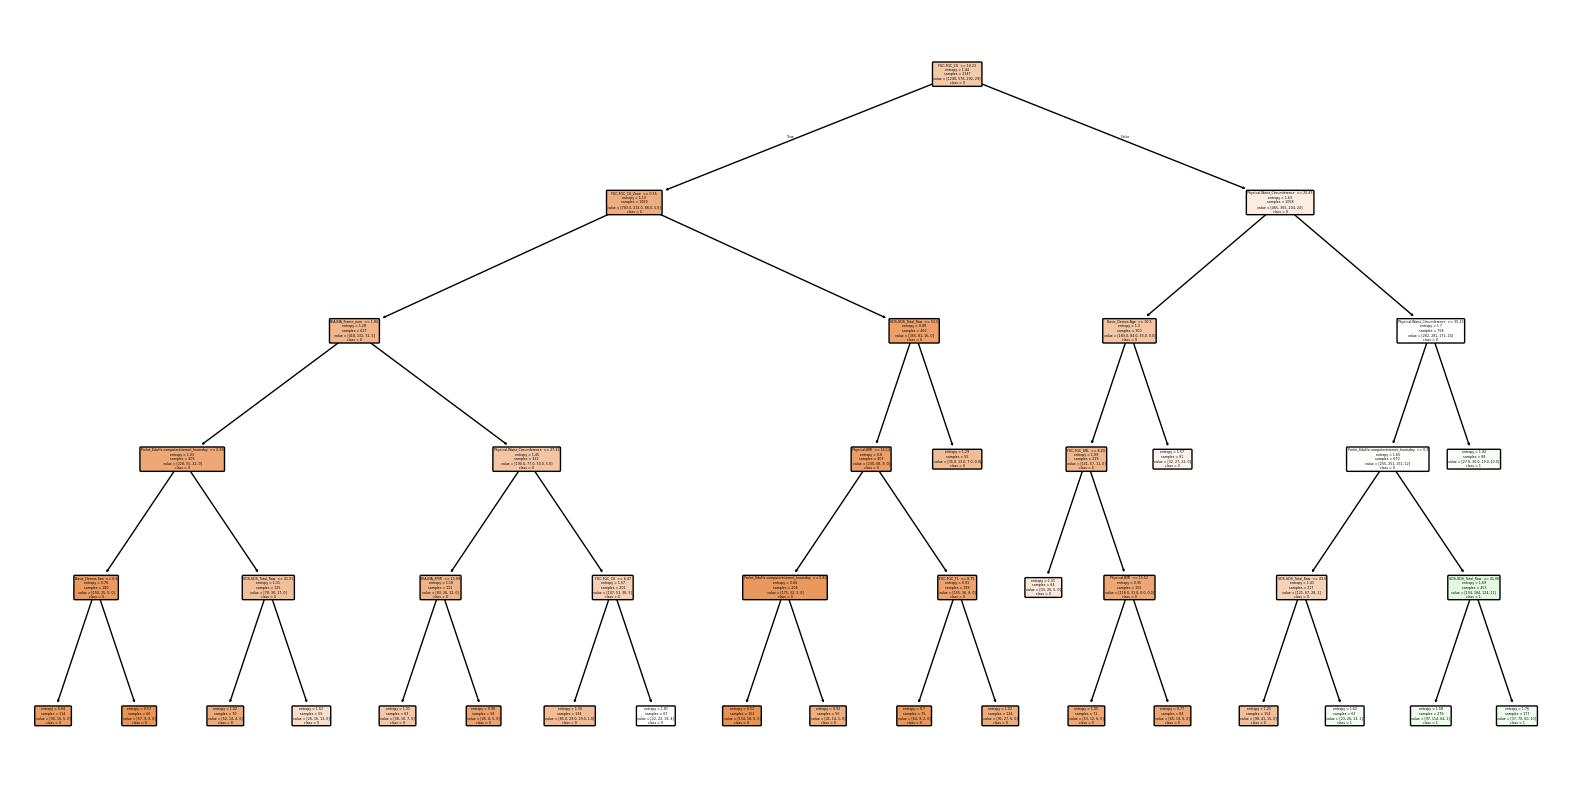

In [244]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10)) 
plot_tree(best_tree, filled=True, feature_names=X_train80.columns, class_names=["0", "1", "2", "3"], 
          rounded=True, proportion=False, precision=2)
plt.show()


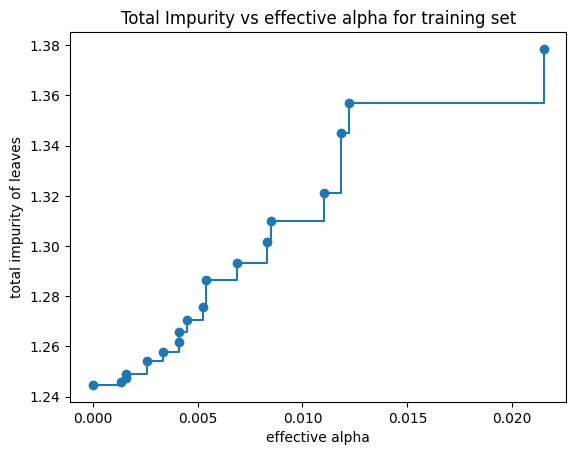

In [245]:
import matplotlib.pyplot as plt

#
# Proviamo a fare pruning usando cross-validation
# Split: 80/20
#

path = best_tree.cost_complexity_pruning_path(X_train80, y_train80)
ccp_alphas, impurities = path.ccp_alphas, path.impurities

fig, ax = plt.subplots()
ax.plot(ccp_alphas[:-1], impurities[:-1], marker="o", drawstyle="steps-post")
ax.set_xlabel("effective alpha")
ax.set_ylabel("total impurity of leaves")
ax.set_title("Total Impurity vs effective alpha for training set");

#
# Alpha vicino a 0.002 -> sembra essere un buon valore
#

In [246]:
# Costruiamo tutti gli alberi con i vari valori di ccp_alpha
ccp_alphas = ccp_alphas[:-1]
dts = []
best_params_grid = grid_search.best_params_
for ccp_alpha in ccp_alphas:
    dt = DecisionTreeClassifier(
        random_state=42, 
        ccp_alpha=ccp_alpha,
        **best_params_grid
    )
    dt.fit(X_train80, y_train80)
    dts.append(dt)

    test_acc = accuracy_score(y_true=y_test20, y_pred=dt.predict(X_test20))

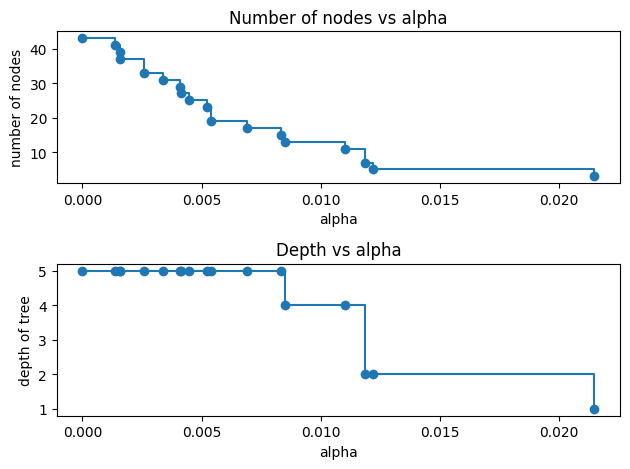

In [247]:
node_counts = [dt.tree_.node_count for dt in dts]
depth = [dt.tree_.max_depth for dt in dts]
fig, ax = plt.subplots(2, 1)
ax[0].plot(ccp_alphas, node_counts, marker="o", drawstyle="steps-post")
ax[0].set_xlabel("alpha")
ax[0].set_ylabel("number of nodes")
ax[0].set_title("Number of nodes vs alpha")
ax[1].plot(ccp_alphas, depth, marker="o", drawstyle="steps-post")
ax[1].set_xlabel("alpha")
ax[1].set_ylabel("depth of tree")
ax[1].set_title("Depth vs alpha")
fig.tight_layout()

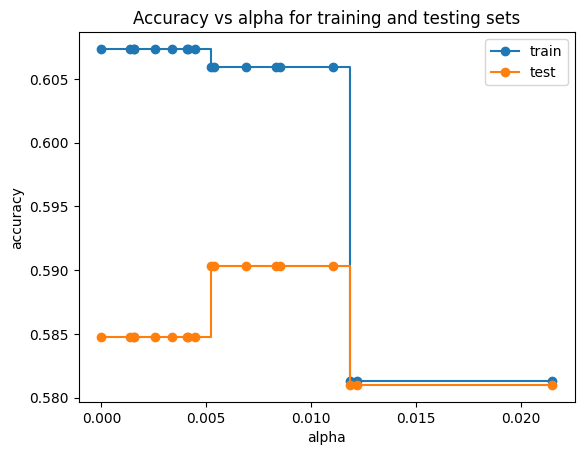

In [248]:
train_scores = [dt.score(X_train80, y_train80) for dt in dts]
test_scores = [dt.score(X_test20, y_test20) for dt in dts]

fig, ax = plt.subplots()
ax.set_xlabel("alpha")
ax.set_ylabel("accuracy")
ax.set_title("Accuracy vs alpha for training and testing sets")
ax.plot(ccp_alphas, train_scores, marker="o", label="train", drawstyle="steps-post")
ax.plot(ccp_alphas, test_scores, marker="o", label="test", drawstyle="steps-post")
ax.legend()
plt.show()

<Axes: xlabel='alpha'>

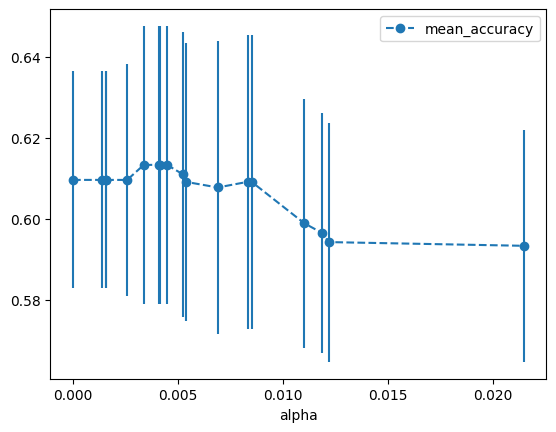

In [249]:
# Controlliamo i valori di alpha per vedere quale è più "consistente" nei dati
# vale a dire, quale valore di alpha ha la media più alta
alpha_loop_values = []
for ccp_alpha in ccp_alphas:
    dt = DecisionTreeClassifier(
        random_state=42, 
        ccp_alpha=ccp_alpha,
        **best_params_grid
    )
    scores = cross_val_score(dt, X_train80, y_train80, cv=20)
    alpha_loop_values.append([ccp_alpha, np.mean(scores), np.std(scores)])

alpha_results = pd.DataFrame(alpha_loop_values, columns=['alpha', 'mean_accuracy', 'std'])

alpha_results.plot(x='alpha', 
                   y='mean_accuracy', 
                   yerr='std', 
                   marker='o', 
                   linestyle='--')

In [250]:
# prendo il valore effettivo di alpha che ha la media più alta
subset = alpha_results[(alpha_results['alpha'] >= 0.0) 
              & (alpha_results['alpha'] < 0.010)]

ideal_alpha = subset.loc[subset['mean_accuracy'].idxmax(), 'alpha']
ideal_alpha = float(ideal_alpha)
print("Miglior valore di alpha:", ideal_alpha)

Miglior valore di alpha: 0.0033742305893569025


In [251]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt

#
# Creo il modello con il valore di alpha ideale
# Split: 80/20
# Mostro la CM per vedere la distribuzione dei valori predetti
#

dt_pruned = DecisionTreeClassifier(
        random_state=42, 
        ccp_alpha=ideal_alpha,
        **best_params_grid
    )
dt_pruned.fit(X_train80, y_train80)
print("Train accuracy:", accuracy_score(y_true=y_train80, y_pred=dt_pruned.predict(X_train80)))
print("Test accuracy:", accuracy_score(y_true=y_test20, y_pred=dt_pruned.predict(X_test20)))

cv_scores = cross_val_score(dt_pruned, X_train80, y_train80, cv=20, scoring="accuracy")

print(f"Cross-Validation Accuracy: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

Train accuracy: 0.607359105728924
Test accuracy: 0.5847299813780261
Cross-Validation Accuracy: 0.6134 ± 0.0343


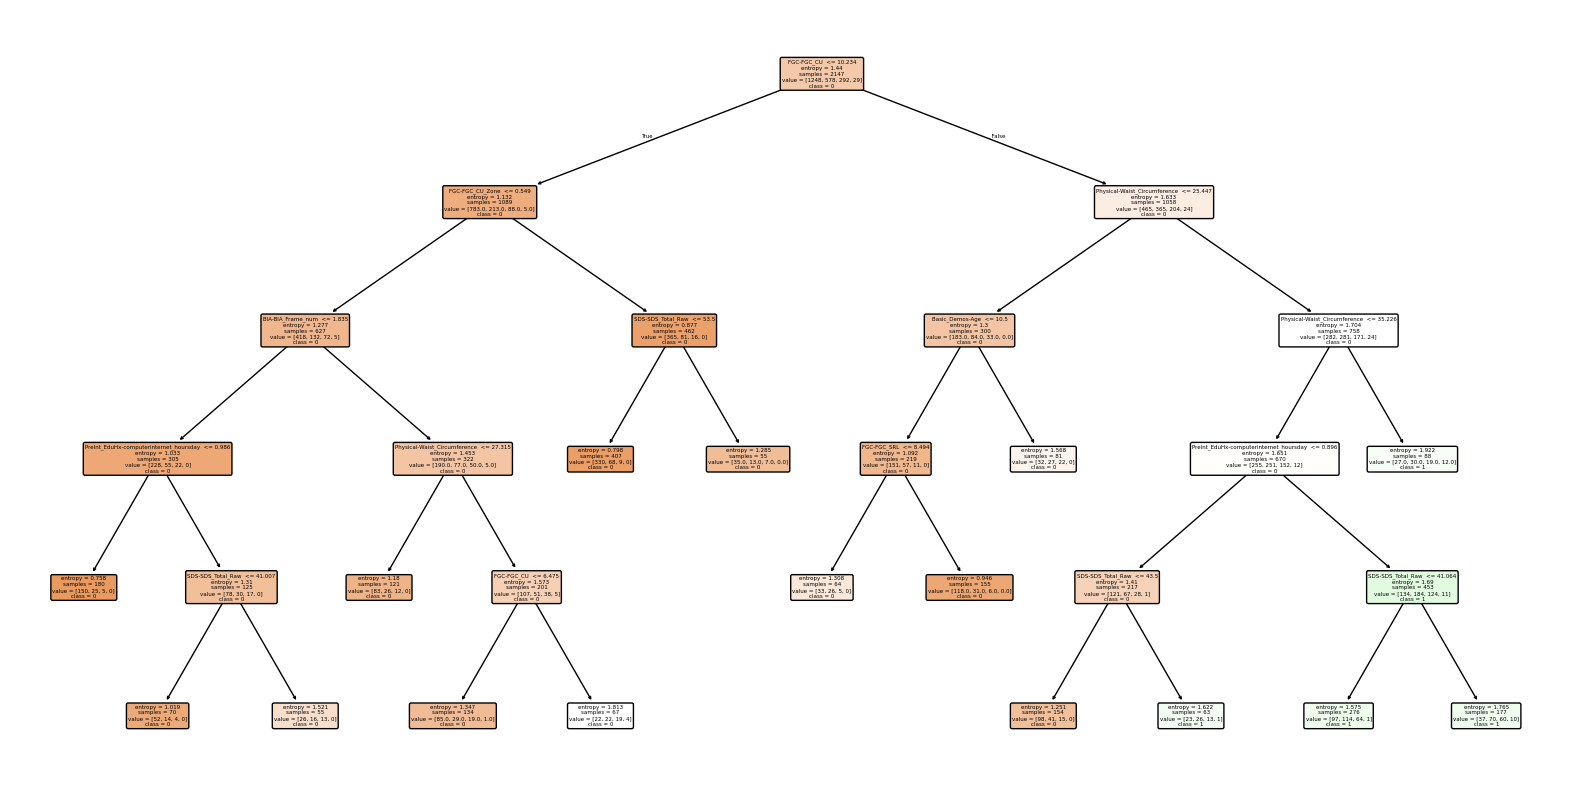

In [252]:
from sklearn.tree import plot_tree

#
# Mostro l'albero di decisione che si va' a crearea usando il valore di alpha ideale
#

plt.figure(figsize=(20,10))
plot_tree(dt_pruned, filled=True, rounded=True, feature_names=X.columns, class_names=["0", "1", "2", "3"])
plt.show()

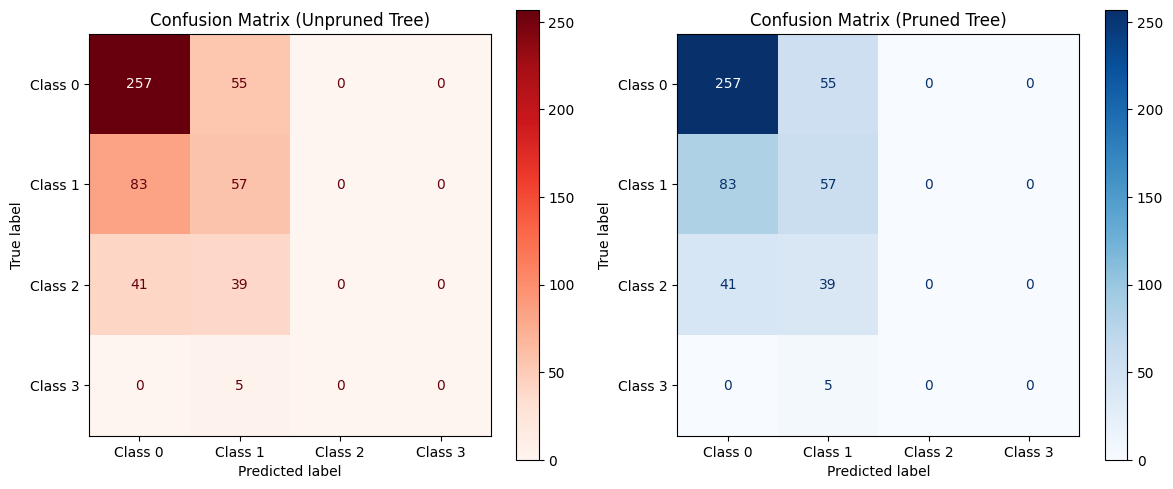

In [253]:
# Mostra la matrice di confusione con etichette
cm_unpruned = confusion_matrix(y_test20, best_tree.predict(X_test20))
cm_pruned = confusion_matrix(y_test20, dt_pruned.predict(X_test20))

# Create subplots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Unpruned tree confusion matrix
disp_unpruned = ConfusionMatrixDisplay(confusion_matrix=cm_unpruned, display_labels=["Class 0", "Class 1", "Class 2", "Class 3"])
disp_unpruned.plot(ax=axes[0], cmap="Reds")
axes[0].set_title("Confusion Matrix (Unpruned Tree)")

# Pruned tree confusion matrix
disp_pruned = ConfusionMatrixDisplay(confusion_matrix=cm_pruned, display_labels=["Class 0", "Class 1", "Class 2", "Class 3"])
disp_pruned.plot(ax=axes[1], cmap="Blues")
axes[1].set_title("Confusion Matrix (Pruned Tree)")

# Adjust layout
plt.tight_layout()
plt.show()

In [254]:
from sklearn.metrics import classification_report

# Predictions for both trees
y_pred_unpruned = best_tree.predict(X_test20)
y_pred_pruned = dt_pruned.predict(X_test20)

# Generate classification reports
report_unpruned = classification_report(y_test20, y_pred_unpruned, target_names=["Class 0", "Class 1", "Class 2", "Class 3"])
report_pruned = classification_report(y_test20, y_pred_pruned, target_names=["Class 0", "Class 1", "Class 2", "Class 3"])

print("=== Classification Report: Unpruned Tree ===")
print(report_unpruned)

print("\n=== Classification Report: Pruned Tree ===")
print(report_pruned)


=== Classification Report: Unpruned Tree ===
              precision    recall  f1-score   support

     Class 0       0.67      0.82      0.74       312
     Class 1       0.37      0.41      0.39       140
     Class 2       0.00      0.00      0.00        80
     Class 3       0.00      0.00      0.00         5

    accuracy                           0.58       537
   macro avg       0.26      0.31      0.28       537
weighted avg       0.49      0.58      0.53       537


=== Classification Report: Pruned Tree ===
              precision    recall  f1-score   support

     Class 0       0.67      0.82      0.74       312
     Class 1       0.37      0.41      0.39       140
     Class 2       0.00      0.00      0.00        80
     Class 3       0.00      0.00      0.00         5

    accuracy                           0.58       537
   macro avg       0.26      0.31      0.28       537
weighted avg       0.49      0.58      0.53       537



/Users/gabrielearmani/Desktop/Università/3 anno/data_and_web_mining/progetto/venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/gabrielearmani/Desktop/Università/3 anno/data_and_web_mining/progetto/venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/gabrielearmani/Desktop/Università/3 anno/data_and_web_mining/progetto/venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0

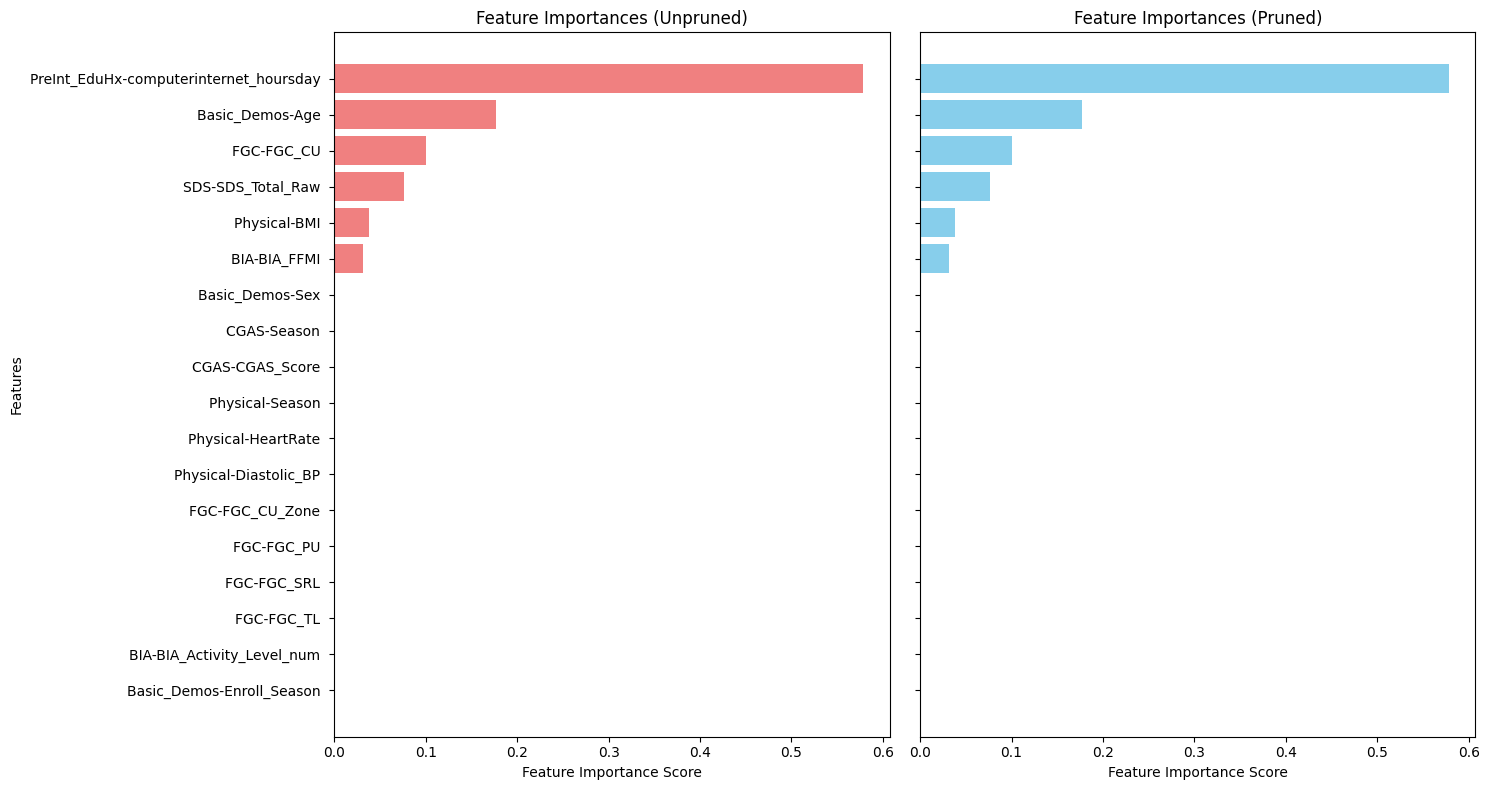

In [220]:
import numpy as np
import matplotlib.pyplot as plt

# Feature importances for both trees
importances_unpruned = best_tree.feature_importances_
importances_pruned = dt_pruned.feature_importances_

# Sort feature importances
sorted_idx_unpruned = np.argsort(importances_unpruned)[::-1]
sorted_idx_pruned = np.argsort(importances_pruned)[::-1]

sorted_features_unpruned = X_train80.columns[sorted_idx_unpruned]
sorted_features_pruned = X_train80.columns[sorted_idx_pruned]

# Create subplots
fig, axes = plt.subplots(1, 2, figsize=(15, 8), sharey=True)

# Unpruned tree plot
axes[0].barh(sorted_features_unpruned, importances_unpruned[sorted_idx_unpruned], color='lightcoral')
axes[0].set_xlabel("Feature Importance Score")
axes[0].set_ylabel("Features")
axes[0].set_title("Feature Importances (Unpruned)")
axes[0].invert_yaxis()

# Pruned tree plot
axes[1].barh(sorted_features_pruned, importances_pruned[sorted_idx_pruned], color='skyblue')
axes[1].set_xlabel("Feature Importance Score")
axes[1].set_title("Feature Importances (Pruned)")

# Show the combined plot
plt.tight_layout()
plt.show()


In [164]:
from sklearn.ensemble import BaggingClassifier

maxScore = -1
bestEstimators = -1
for i in range(1, 51):
   bagged_dt = BaggingClassifier(estimator=best_tree, n_estimators=i, random_state=42)
   cv_scores = cross_val_score(bagged_dt, X_train80, y_train80, cv=5, scoring='accuracy')
   mean_cv_score = cv_scores.mean()  # Media dell'accuratezza nei fold
   
   if mean_cv_score > maxScore:
       maxScore = mean_cv_score
       bestEstimators = i

# Una volta trovato il migliore n_estimators, allena il modello finale
bestDt_bagging = BaggingClassifier(estimator=best_tree, n_estimators=bestEstimators, random_state=42)
bestDt_bagging.fit(X_train80, y_train80)

print("bestEstimators:", bestEstimators)
print("Accuracy: {:.3f}".format(accuracy_score(y_true=y_test20, y_pred=bestDt_bagging.predict(X_test20))))

cv_scores = cross_val_score(bestDt_bagging, X_train80, y_train80, cv=20, scoring='accuracy')

print(f"Accuracy media: {cv_scores.mean()}")
print(f"Standard Deviation: {cv_scores.std()}")


bestEstimators: 5
Accuracy: 0.570
Accuracy media: 0.6059103496019383
Standard Deviation: 0.035153462973617856


Error/Bias/Variance at the last iteration: [0.66378026 0.57867318 0.08510708]


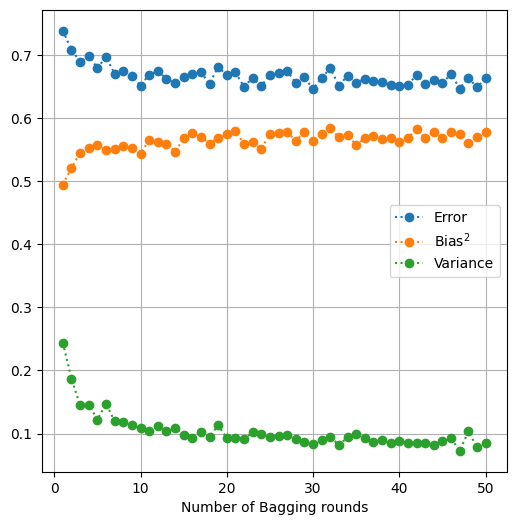

In [165]:
from sklearn.utils import resample
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier

N_TESTS = 20
stats = np.array([])
bags = range(1,51)
for l in bags:
    y_preds = np.array([])
    
    for i in range(N_TESTS):
        Xs, ys = resample(X_train80, y_train80, n_samples=int(0.67*len(y_train80)) )

        # train a decision tree classifier
        dt = DecisionTreeClassifier(
                max_depth=int(best_params_grid['max_depth']),
                min_samples_split=int(best_params_grid['min_samples_split']),
                min_samples_leaf=int(best_params_grid['min_samples_leaf']),
                criterion='gini',
                max_features=None, # best_params['max_features'],
                ccp_alpha=ideal_alpha,
                random_state=42
            )
        bagged_dt = BaggingClassifier(estimator=dt, n_estimators=l, random_state=42)
        bagged_dt.fit(Xs,ys)
        
        y_pred = bagged_dt.predict(X_test20)
        y_preds = np.column_stack( [y_preds, y_pred] ) if y_preds.size else y_pred

    dt_bias     = (y_test20-np.mean(y_preds,axis=1))**2
    dt_variance = np.var(y_preds,axis=1)
    dt_error = (y_preds - y_test20.to_numpy().reshape(-1, 1))**2

    run_stats = np.array([dt_error.mean(), dt_bias.mean(), dt_variance.mean()])
    
    stats = np.column_stack( [stats, run_stats]) if stats.size else run_stats

fig, ax = plt.subplots(figsize=(6,6))

ax.plot(bags,stats[0,:], 'o:', label='Error')
ax.plot(bags,stats[1,:], 'o:', label='Bias$^2$')
ax.plot(bags,stats[2,:], 'o:', label='Variance')
ax.set_xlabel('Number of Bagging rounds')
ax.grid()
ax.legend()

print ("Error/Bias/Variance at the last iteration:", stats[:,-1])

In [38]:
from sklearn.ensemble import AdaBoostClassifier

adaboost = AdaBoostClassifier(best_tree, n_estimators=10, random_state=42)

adaboost.fit(X_train80,y_train80)
print ("Accuracy:", accuracy_score(y_true=y_test20, y_pred=adaboost.predict(X_test20) ))

Accuracy: 0.5493482309124768


Error/Bias/Variance at the last iteration: [0.81312849 0.47595438 0.33717412]


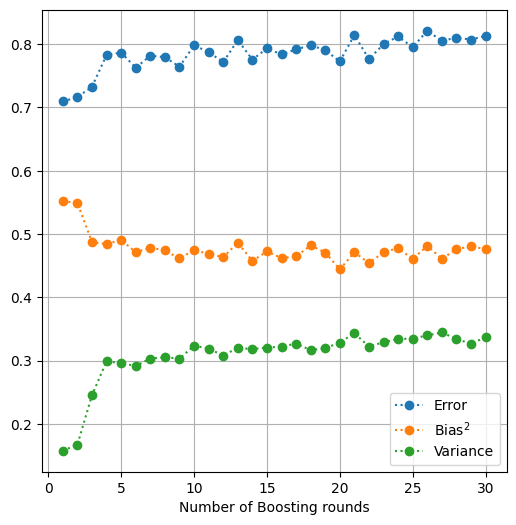

In [39]:
from sklearn.utils import resample
from sklearn.ensemble import AdaBoostClassifier

N_TESTS = 20
stats = np.array([])
boosts = range(1,31)
for l in boosts:
    y_preds = np.array([])
    
    for i in range(N_TESTS):
        Xs, ys = resample(X_train80, y_train80, n_samples=int(0.67*len(y_train80)) )

        # train a decision tree classifier
        dt = DecisionTreeClassifier(
                max_depth=int(best_params_grid['max_depth']),
                min_samples_split=int(best_params_grid['min_samples_split']),
                min_samples_leaf=int(best_params_grid['min_samples_leaf']),
                criterion='gini',
                max_features=None, # best_params['max_features'],
                ccp_alpha=ideal_alpha,
                random_state=42
            )
        adaboost = AdaBoostClassifier(estimator=dt, n_estimators=l, random_state=42)
        adaboost.fit(Xs,ys)
        
        y_pred = adaboost.predict(X_test20)
        y_preds = np.column_stack( [y_preds, y_pred] ) if y_preds.size else y_pred

    dt_bias     = (y_test20 - np.mean(y_preds, axis=1))**2
    dt_variance = np.var(y_preds, axis=1)
    dt_error    = (y_preds - y_test20.to_numpy().reshape(-1,1))**2

    run_stats = np.array([dt_error.mean(), dt_bias.mean(), dt_variance.mean()])
    
    stats = np.column_stack( [stats, run_stats]) if stats.size else run_stats
    
fig, ax = plt.subplots(figsize=(6,6))

ax.plot(boosts,stats[0,:], 'o:', label='Error')
ax.plot(boosts,stats[1,:], 'o:', label='Bias$^2$')
ax.plot(boosts,stats[2,:], 'o:', label='Variance')
ax.set_xlabel('Number of Boosting rounds')
ax.grid()
ax.legend()

print ("Error/Bias/Variance at the last iteration:", stats[:,-1])

In [40]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf = RandomForestClassifier(random_state=42)
rf.fit(X_train80, y_train80)
accuracy_rf = accuracy_score(y_test20, rf.predict(X_test20))

print(f"Random Forest - Test Accuracy: {accuracy_rf:.3f}")


Random Forest - Test Accuracy: 0.594


In [41]:
from sklearn.model_selection import RandomizedSearchCV

n_est = [int(x) for x in np.linspace(start = 50, stop = 500, num = 10)]
max_dep = [int(x) for x in np.linspace(1, 25, num = 5)]
param_grid = {
    'n_estimators': n_est,
    'max_depth': max_dep,
    'min_samples_split': [2, 5, 10, 15, 20],
    'min_samples_leaf': [1, 2, 4, 10, 15, 20],
    'max_features': [None, 'sqrt', 'log2'],
    'bootstrap': [True, False]
}

rf = RandomForestClassifier(random_state=42)
Random_search = RandomizedSearchCV(rf, param_distributions=param_grid, 
                                   n_iter=100, cv=5, n_jobs=-1, verbose=0, random_state=42, error_score='raise')
Random_search.fit(X_train80, y_train80)

print("Best Parameters:", Random_search.best_params_)


Best Parameters: {'n_estimators': 250, 'min_samples_split': 20, 'min_samples_leaf': 4, 'max_features': None, 'max_depth': 7, 'bootstrap': True}


In [42]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

best_rf_params = Random_search.best_params_
param_grid = {
    'max_depth': range(max(1, best_rf_params['max_depth']-2), best_rf_params['max_depth']+2),
    'min_samples_split': range(max(2, best_rf_params['min_samples_split']-2), best_rf_params['min_samples_split']+2),
    'min_samples_leaf': range(max(1, best_rf_params['min_samples_leaf']-2), best_rf_params['min_samples_leaf']+2),
    'max_features': [best_rf_params['max_features']],
    'bootstrap': [best_rf_params['bootstrap']],
    'n_estimators': [best_rf_params['n_estimators']-20, best_rf_params['n_estimators']-10,
                     best_rf_params['n_estimators'],
                     best_rf_params['n_estimators']+10, best_rf_params['n_estimators']-20]
            }

rf = RandomForestClassifier(random_state=42)
Grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, 
                           cv=5, n_jobs=-1, verbose=0, scoring='accuracy')
Grid_search.fit(X_train80, y_train80)

print("Best Parameters from Grid Search:", Grid_search.best_params_)

best_grid_rf = Grid_search.best_estimator_
test_accuracy = accuracy_score(y_test20, best_grid_rf.predict(X_test20))
print(f"Random Forest - Test Accuracy (after Grid Search): {test_accuracy:.3f}")


Best Parameters from Grid Search: {'bootstrap': True, 'max_depth': 7, 'max_features': None, 'min_samples_leaf': 4, 'min_samples_split': 20, 'n_estimators': 260}
Random Forest - Test Accuracy (after Grid Search): 0.587
